# 인공 신경망

<table align="left"><tr><td>
<a href="https://colab.research.google.com/github/rickiepark/hg-mldl2/blob/main/07-1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="코랩에서 실행하기"/></a>
</td></tr></table>

In [25]:
# 실행마다 동일한 결과를 얻기 위해 케라스에 랜덤 시드를 사용하고 텐서플로 연산을 결정적으로 만듭니다.
import keras
import tensorflow as tf

keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

## 패션 MNIST

In [26]:
import keras

(train_input, train_target), (test_input, test_target) = \
    keras.datasets.fashion_mnist.load_data()

In [27]:
print(train_input.shape, train_target.shape)

(60000, 28, 28) (60000,)


In [28]:
print(test_input.shape, test_target.shape)

(10000, 28, 28) (10000,)


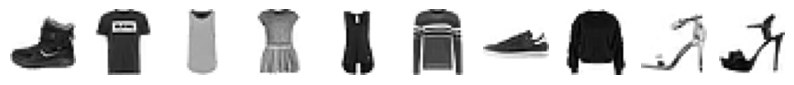

In [29]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 10, figsize=(10,10))
for i in range(10):
    axs[i].imshow(train_input[i], cmap='gray_r')
    axs[i].axis('off')
plt.show()

In [30]:
print(train_target[:10])

[9 0 0 3 0 2 7 2 5 5]


In [31]:
import numpy as np

print(np.unique(train_target, return_counts=True))

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8), array([6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]))


## 로지스틱 회귀로 패션 아이템 분류하기

In [32]:
train_scaled = train_input / 255.0
train_scaled = train_scaled.reshape(-1, 28*28)

In [33]:
print(train_scaled.shape)

(60000, 784)


In [34]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import SGDClassifier

sc = SGDClassifier(loss='log_loss', max_iter=5, random_state=42)
scores = cross_validate(sc, train_scaled, train_target, n_jobs=-1)
print(np.mean(scores['test_score']))

0.8194166666666666


## 인공신경망

### 텐서플로와 케라스

In [35]:
import tensorflow as tf

In [36]:
import keras

In [37]:
keras.config.backend()

'tensorflow'

In [38]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # 또는 "jax"

## 인공신경망으로 모델 만들기

In [39]:
from sklearn.model_selection import train_test_split

train_scaled, val_scaled, train_target, val_target = train_test_split(
    train_scaled, train_target, test_size=0.2, random_state=42)

In [40]:
print(train_scaled.shape, train_target.shape)

(48000, 784) (48000,)


In [41]:
print(val_scaled.shape, val_target.shape)

(12000, 784) (12000,)


In [42]:
inputs = keras.layers.Input(shape=(784,))

In [43]:
dense = keras.layers.Dense(10, activation='softmax')

In [44]:
model = keras.Sequential([inputs, dense])

## 인공신경망으로 패션 아이템 분류하기

In [45]:
model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [46]:
print(train_target[:10])

[7 3 5 8 6 9 3 3 9 9]


In [47]:
model.fit(train_scaled, train_target, epochs=5)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7947 - loss: 0.6069
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8388 - loss: 0.4742
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8470 - loss: 0.4501
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8512 - loss: 0.4374
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8544 - loss: 0.4291


In [48]:
model.evaluate(val_scaled, val_target)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8458 - loss: 0.4444


[0.4444445073604584, 0.8458333611488342]

Epoch  1/10 | train loss: 0.6094 | val loss: 0.5171 | val accuracy: 0.8250
Epoch  2/10 | train loss: 0.4914 | val loss: 0.4647 | val accuracy: 0.8383
Epoch  3/10 | train loss: 0.4706 | val loss: 0.4926 | val accuracy: 0.8283
Epoch  4/10 | train loss: 0.4558 | val loss: 0.4601 | val accuracy: 0.8450
Epoch  5/10 | train loss: 0.4455 | val loss: 0.4485 | val accuracy: 0.8434
Epoch  6/10 | train loss: 0.4422 | val loss: 0.4587 | val accuracy: 0.8482
Epoch  7/10 | train loss: 0.4387 | val loss: 0.4769 | val accuracy: 0.8387
Epoch  8/10 | train loss: 0.4329 | val loss: 0.4857 | val accuracy: 0.8275
Epoch  9/10 | train loss: 0.4284 | val loss: 0.4367 | val accuracy: 0.8487
Epoch 10/10 | train loss: 0.4256 | val loss: 0.6069 | val accuracy: 0.7943


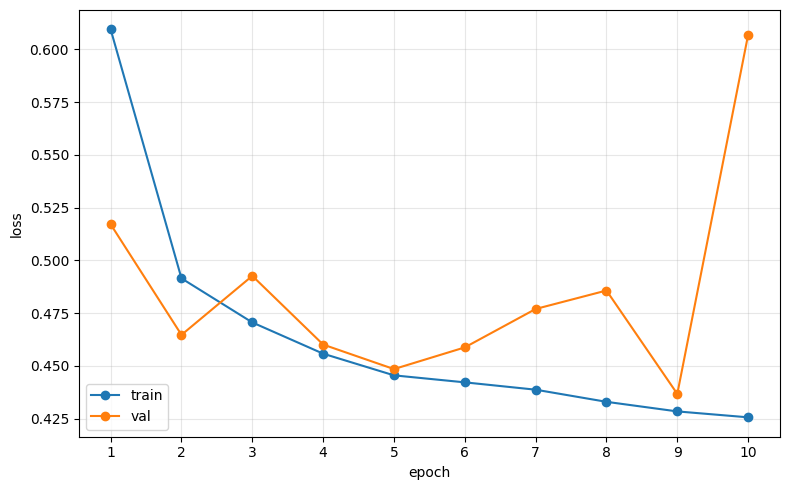

In [50]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# 데이터 준비 (이미 텐서여도 사용 가능)
x_train = torch.as_tensor(train_scaled, dtype=torch.float32)
y_train = torch.as_tensor(train_target, dtype=torch.long)
x_val = torch.as_tensor(val_scaled, dtype=torch.float32).to(device)
y_val = torch.as_tensor(val_target, dtype=torch.long).to(device)

train_loader = DataLoader(
    TensorDataset(x_train, y_train),
    batch_size=32,
    shuffle=True
)

# 28×28 이미지, 10개 클래스를 분류하는 1층 신경망
# CrossEntropyLoss를 사용하므로 마지막에 Softmax를 넣지 않습니다.
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 10)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

train_hist = []
val_hist = []

for epoch in range(10):
    # 1. 훈련
    model.train()
    total_loss = 0.0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        # 배치 크기를 반영하여 전체 평균 loss 계산
        total_loss += loss.item() * inputs.size(0)

    train_loss = total_loss / len(train_loader.dataset)

    # 2. 검증
    model.eval()
    with torch.no_grad():
        outputs = model(x_val)
        val_loss = criterion(outputs, y_val).item()

        predicts = torch.argmax(outputs, dim=1)
        accuracy = (predicts == y_val).float().mean().item()

    # 3. 에포크별 loss 기록
    train_hist.append(train_loss)
    val_hist.append(val_loss)

    print(
        f"Epoch {epoch + 1:2d}/10 | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {val_loss:.4f} | "
        f"val accuracy: {accuracy:.4f}"
    )

# 4. 훈련·검증 loss 그래프
epochs = range(1, 11)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_hist, label="train", marker="o")
plt.plot(epochs, val_hist, label="val", marker="o")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
